# Outlier detection and treatment with restaurant bills
**Beginner follow-along notebook · live demo at minutes 54–67**

Our question: **Should a restaurant automatically discard an unusually large bill?**
Flow: **notice → detect → investigate → treat → check the effect**.
By the end you can use an IQR rule, explain its limitations, and compare treatment choices.

Run the six sections marked **LIVE A–F** during class. Pre-run them before screen sharing;
students should predict the output before you reveal it. The appendices are optional self-study.
No ML modelling knowledge is required for the live sections. Basic pandas helps, but the mentor
can run all code while students interpret the pictures.

Use Python 3.12 and the accompanying requirements file. From a fresh environment:
`python -m pip install -r requirements.txt`. In Colab, the standard libraries are normally present.
This notebook includes the real CSV as an offline fallback; no dataset download is required.

## Sources and data limitations
The tips data describes 244 meals recorded by one waiter at one restaurant over a few months.
Bill and tip amounts are US dollars; `size` is party size. It is a small historical convenience
sample, not a picture of current prices or a representative population. There are **no verified
outlier/error labels**. A statistical flag is not a proven error or fraud label.

- Data documentation and original reference: [R tips documentation](https://search.r-project.org/CRAN/refmans/reshape/html/tips.html).
  Bryant and Smith (1995), *Practical Data Analysis: Case Studies in Business Statistics*.
- CSV distribution: [seaborn-data tips.csv](https://github.com/mwaskom/seaborn-data/blob/master/tips.csv).
- [scikit-learn outlier guide](https://scikit-learn.org/stable/modules/outlier_detection.html).
- [IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)
  and [LocalOutlierFactor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html).
- [PyOD IForest](https://pyod.readthedocs.io/en/latest/_modules/pyod/models/iforest.html).
- [Feature-engine Winsorizer](https://feature-engine.trainindata.com/en/latest/user_guide/outliers/Winsorizer.html).

Only numeric restaurant context is used in detection. The demographic columns are not needed for this lesson.

## Global, contextual and collective outliers

| Type | What is unusual? | Example |
|---|---|---|
| Global / point | One record differs from the overall pattern | A very large bill among mostly small bills |
| Contextual | A record differs within a relevant group or situation | A large bill for one diner, even if ordinary for six diners |
| Collective | A sequence or group is unusual together | A sensor remains exactly constant for an hour although individual readings are plausible |

Univariate versus multivariate describes the number of features used; it is a separate distinction.
Our pooled bill IQR rule checks global extremes. Party size supplies context. This dataset lacks
full timestamps, so it does not demonstrate collective time-series detection.


## LIVE A · Meet the data and reserve a test set · 2 minutes
One row is one meal. We will focus on bill size, party size, and tip.
Reserve 25% of rows before learning any statistical thresholds. The training rows are our
reference; the held-out rows represent later arrivals. The random split is a teaching
simplification: a deployed restaurant system would usually use timestamps and a time split.
The source has no full dates, so we cannot demonstrate that faithfully here.

In [1]:
from pathlib import Path
from io import StringIO
import sys, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# A small real dataset is embedded so this notebook also works alone in Colab.
# Prefer the bundled, unchanged CSV when the whole pack is extracted.
DATA_CSV = '"total_bill","tip","sex","smoker","day","time","size"\n16.99,1.01,"Female","No","Sun","Dinner",2\n10.34,1.66,"Male","No","Sun","Dinner",3\n21.01,3.5,"Male","No","Sun","Dinner",3\n23.68,3.31,"Male","No","Sun","Dinner",2\n24.59,3.61,"Female","No","Sun","Dinner",4\n25.29,4.71,"Male","No","Sun","Dinner",4\n8.77,2,"Male","No","Sun","Dinner",2\n26.88,3.12,"Male","No","Sun","Dinner",4\n15.04,1.96,"Male","No","Sun","Dinner",2\n14.78,3.23,"Male","No","Sun","Dinner",2\n10.27,1.71,"Male","No","Sun","Dinner",2\n35.26,5,"Female","No","Sun","Dinner",4\n15.42,1.57,"Male","No","Sun","Dinner",2\n18.43,3,"Male","No","Sun","Dinner",4\n14.83,3.02,"Female","No","Sun","Dinner",2\n21.58,3.92,"Male","No","Sun","Dinner",2\n10.33,1.67,"Female","No","Sun","Dinner",3\n16.29,3.71,"Male","No","Sun","Dinner",3\n16.97,3.5,"Female","No","Sun","Dinner",3\n20.65,3.35,"Male","No","Sat","Dinner",3\n17.92,4.08,"Male","No","Sat","Dinner",2\n20.29,2.75,"Female","No","Sat","Dinner",2\n15.77,2.23,"Female","No","Sat","Dinner",2\n39.42,7.58,"Male","No","Sat","Dinner",4\n19.82,3.18,"Male","No","Sat","Dinner",2\n17.81,2.34,"Male","No","Sat","Dinner",4\n13.37,2,"Male","No","Sat","Dinner",2\n12.69,2,"Male","No","Sat","Dinner",2\n21.7,4.3,"Male","No","Sat","Dinner",2\n19.65,3,"Female","No","Sat","Dinner",2\n9.55,1.45,"Male","No","Sat","Dinner",2\n18.35,2.5,"Male","No","Sat","Dinner",4\n15.06,3,"Female","No","Sat","Dinner",2\n20.69,2.45,"Female","No","Sat","Dinner",4\n17.78,3.27,"Male","No","Sat","Dinner",2\n24.06,3.6,"Male","No","Sat","Dinner",3\n16.31,2,"Male","No","Sat","Dinner",3\n16.93,3.07,"Female","No","Sat","Dinner",3\n18.69,2.31,"Male","No","Sat","Dinner",3\n31.27,5,"Male","No","Sat","Dinner",3\n16.04,2.24,"Male","No","Sat","Dinner",3\n17.46,2.54,"Male","No","Sun","Dinner",2\n13.94,3.06,"Male","No","Sun","Dinner",2\n9.68,1.32,"Male","No","Sun","Dinner",2\n30.4,5.6,"Male","No","Sun","Dinner",4\n18.29,3,"Male","No","Sun","Dinner",2\n22.23,5,"Male","No","Sun","Dinner",2\n32.4,6,"Male","No","Sun","Dinner",4\n28.55,2.05,"Male","No","Sun","Dinner",3\n18.04,3,"Male","No","Sun","Dinner",2\n12.54,2.5,"Male","No","Sun","Dinner",2\n10.29,2.6,"Female","No","Sun","Dinner",2\n34.81,5.2,"Female","No","Sun","Dinner",4\n9.94,1.56,"Male","No","Sun","Dinner",2\n25.56,4.34,"Male","No","Sun","Dinner",4\n19.49,3.51,"Male","No","Sun","Dinner",2\n38.01,3,"Male","Yes","Sat","Dinner",4\n26.41,1.5,"Female","No","Sat","Dinner",2\n11.24,1.76,"Male","Yes","Sat","Dinner",2\n48.27,6.73,"Male","No","Sat","Dinner",4\n20.29,3.21,"Male","Yes","Sat","Dinner",2\n13.81,2,"Male","Yes","Sat","Dinner",2\n11.02,1.98,"Male","Yes","Sat","Dinner",2\n18.29,3.76,"Male","Yes","Sat","Dinner",4\n17.59,2.64,"Male","No","Sat","Dinner",3\n20.08,3.15,"Male","No","Sat","Dinner",3\n16.45,2.47,"Female","No","Sat","Dinner",2\n3.07,1,"Female","Yes","Sat","Dinner",1\n20.23,2.01,"Male","No","Sat","Dinner",2\n15.01,2.09,"Male","Yes","Sat","Dinner",2\n12.02,1.97,"Male","No","Sat","Dinner",2\n17.07,3,"Female","No","Sat","Dinner",3\n26.86,3.14,"Female","Yes","Sat","Dinner",2\n25.28,5,"Female","Yes","Sat","Dinner",2\n14.73,2.2,"Female","No","Sat","Dinner",2\n10.51,1.25,"Male","No","Sat","Dinner",2\n17.92,3.08,"Male","Yes","Sat","Dinner",2\n27.2,4,"Male","No","Thur","Lunch",4\n22.76,3,"Male","No","Thur","Lunch",2\n17.29,2.71,"Male","No","Thur","Lunch",2\n19.44,3,"Male","Yes","Thur","Lunch",2\n16.66,3.4,"Male","No","Thur","Lunch",2\n10.07,1.83,"Female","No","Thur","Lunch",1\n32.68,5,"Male","Yes","Thur","Lunch",2\n15.98,2.03,"Male","No","Thur","Lunch",2\n34.83,5.17,"Female","No","Thur","Lunch",4\n13.03,2,"Male","No","Thur","Lunch",2\n18.28,4,"Male","No","Thur","Lunch",2\n24.71,5.85,"Male","No","Thur","Lunch",2\n21.16,3,"Male","No","Thur","Lunch",2\n28.97,3,"Male","Yes","Fri","Dinner",2\n22.49,3.5,"Male","No","Fri","Dinner",2\n5.75,1,"Female","Yes","Fri","Dinner",2\n16.32,4.3,"Female","Yes","Fri","Dinner",2\n22.75,3.25,"Female","No","Fri","Dinner",2\n40.17,4.73,"Male","Yes","Fri","Dinner",4\n27.28,4,"Male","Yes","Fri","Dinner",2\n12.03,1.5,"Male","Yes","Fri","Dinner",2\n21.01,3,"Male","Yes","Fri","Dinner",2\n12.46,1.5,"Male","No","Fri","Dinner",2\n11.35,2.5,"Female","Yes","Fri","Dinner",2\n15.38,3,"Female","Yes","Fri","Dinner",2\n44.3,2.5,"Female","Yes","Sat","Dinner",3\n22.42,3.48,"Female","Yes","Sat","Dinner",2\n20.92,4.08,"Female","No","Sat","Dinner",2\n15.36,1.64,"Male","Yes","Sat","Dinner",2\n20.49,4.06,"Male","Yes","Sat","Dinner",2\n25.21,4.29,"Male","Yes","Sat","Dinner",2\n18.24,3.76,"Male","No","Sat","Dinner",2\n14.31,4,"Female","Yes","Sat","Dinner",2\n14,3,"Male","No","Sat","Dinner",2\n7.25,1,"Female","No","Sat","Dinner",1\n38.07,4,"Male","No","Sun","Dinner",3\n23.95,2.55,"Male","No","Sun","Dinner",2\n25.71,4,"Female","No","Sun","Dinner",3\n17.31,3.5,"Female","No","Sun","Dinner",2\n29.93,5.07,"Male","No","Sun","Dinner",4\n10.65,1.5,"Female","No","Thur","Lunch",2\n12.43,1.8,"Female","No","Thur","Lunch",2\n24.08,2.92,"Female","No","Thur","Lunch",4\n11.69,2.31,"Male","No","Thur","Lunch",2\n13.42,1.68,"Female","No","Thur","Lunch",2\n14.26,2.5,"Male","No","Thur","Lunch",2\n15.95,2,"Male","No","Thur","Lunch",2\n12.48,2.52,"Female","No","Thur","Lunch",2\n29.8,4.2,"Female","No","Thur","Lunch",6\n8.52,1.48,"Male","No","Thur","Lunch",2\n14.52,2,"Female","No","Thur","Lunch",2\n11.38,2,"Female","No","Thur","Lunch",2\n22.82,2.18,"Male","No","Thur","Lunch",3\n19.08,1.5,"Male","No","Thur","Lunch",2\n20.27,2.83,"Female","No","Thur","Lunch",2\n11.17,1.5,"Female","No","Thur","Lunch",2\n12.26,2,"Female","No","Thur","Lunch",2\n18.26,3.25,"Female","No","Thur","Lunch",2\n8.51,1.25,"Female","No","Thur","Lunch",2\n10.33,2,"Female","No","Thur","Lunch",2\n14.15,2,"Female","No","Thur","Lunch",2\n16,2,"Male","Yes","Thur","Lunch",2\n13.16,2.75,"Female","No","Thur","Lunch",2\n17.47,3.5,"Female","No","Thur","Lunch",2\n34.3,6.7,"Male","No","Thur","Lunch",6\n41.19,5,"Male","No","Thur","Lunch",5\n27.05,5,"Female","No","Thur","Lunch",6\n16.43,2.3,"Female","No","Thur","Lunch",2\n8.35,1.5,"Female","No","Thur","Lunch",2\n18.64,1.36,"Female","No","Thur","Lunch",3\n11.87,1.63,"Female","No","Thur","Lunch",2\n9.78,1.73,"Male","No","Thur","Lunch",2\n7.51,2,"Male","No","Thur","Lunch",2\n14.07,2.5,"Male","No","Sun","Dinner",2\n13.13,2,"Male","No","Sun","Dinner",2\n17.26,2.74,"Male","No","Sun","Dinner",3\n24.55,2,"Male","No","Sun","Dinner",4\n19.77,2,"Male","No","Sun","Dinner",4\n29.85,5.14,"Female","No","Sun","Dinner",5\n48.17,5,"Male","No","Sun","Dinner",6\n25,3.75,"Female","No","Sun","Dinner",4\n13.39,2.61,"Female","No","Sun","Dinner",2\n16.49,2,"Male","No","Sun","Dinner",4\n21.5,3.5,"Male","No","Sun","Dinner",4\n12.66,2.5,"Male","No","Sun","Dinner",2\n16.21,2,"Female","No","Sun","Dinner",3\n13.81,2,"Male","No","Sun","Dinner",2\n17.51,3,"Female","Yes","Sun","Dinner",2\n24.52,3.48,"Male","No","Sun","Dinner",3\n20.76,2.24,"Male","No","Sun","Dinner",2\n31.71,4.5,"Male","No","Sun","Dinner",4\n10.59,1.61,"Female","Yes","Sat","Dinner",2\n10.63,2,"Female","Yes","Sat","Dinner",2\n50.81,10,"Male","Yes","Sat","Dinner",3\n15.81,3.16,"Male","Yes","Sat","Dinner",2\n7.25,5.15,"Male","Yes","Sun","Dinner",2\n31.85,3.18,"Male","Yes","Sun","Dinner",2\n16.82,4,"Male","Yes","Sun","Dinner",2\n32.9,3.11,"Male","Yes","Sun","Dinner",2\n17.89,2,"Male","Yes","Sun","Dinner",2\n14.48,2,"Male","Yes","Sun","Dinner",2\n9.6,4,"Female","Yes","Sun","Dinner",2\n34.63,3.55,"Male","Yes","Sun","Dinner",2\n34.65,3.68,"Male","Yes","Sun","Dinner",4\n23.33,5.65,"Male","Yes","Sun","Dinner",2\n45.35,3.5,"Male","Yes","Sun","Dinner",3\n23.17,6.5,"Male","Yes","Sun","Dinner",4\n40.55,3,"Male","Yes","Sun","Dinner",2\n20.69,5,"Male","No","Sun","Dinner",5\n20.9,3.5,"Female","Yes","Sun","Dinner",3\n30.46,2,"Male","Yes","Sun","Dinner",5\n18.15,3.5,"Female","Yes","Sun","Dinner",3\n23.1,4,"Male","Yes","Sun","Dinner",3\n15.69,1.5,"Male","Yes","Sun","Dinner",2\n19.81,4.19,"Female","Yes","Thur","Lunch",2\n28.44,2.56,"Male","Yes","Thur","Lunch",2\n15.48,2.02,"Male","Yes","Thur","Lunch",2\n16.58,4,"Male","Yes","Thur","Lunch",2\n7.56,1.44,"Male","No","Thur","Lunch",2\n10.34,2,"Male","Yes","Thur","Lunch",2\n43.11,5,"Female","Yes","Thur","Lunch",4\n13,2,"Female","Yes","Thur","Lunch",2\n13.51,2,"Male","Yes","Thur","Lunch",2\n18.71,4,"Male","Yes","Thur","Lunch",3\n12.74,2.01,"Female","Yes","Thur","Lunch",2\n13,2,"Female","Yes","Thur","Lunch",2\n16.4,2.5,"Female","Yes","Thur","Lunch",2\n20.53,4,"Male","Yes","Thur","Lunch",4\n16.47,3.23,"Female","Yes","Thur","Lunch",3\n26.59,3.41,"Male","Yes","Sat","Dinner",3\n38.73,3,"Male","Yes","Sat","Dinner",4\n24.27,2.03,"Male","Yes","Sat","Dinner",2\n12.76,2.23,"Female","Yes","Sat","Dinner",2\n30.06,2,"Male","Yes","Sat","Dinner",3\n25.89,5.16,"Male","Yes","Sat","Dinner",4\n48.33,9,"Male","No","Sat","Dinner",4\n13.27,2.5,"Female","Yes","Sat","Dinner",2\n28.17,6.5,"Female","Yes","Sat","Dinner",3\n12.9,1.1,"Female","Yes","Sat","Dinner",2\n28.15,3,"Male","Yes","Sat","Dinner",5\n11.59,1.5,"Male","Yes","Sat","Dinner",2\n7.74,1.44,"Male","Yes","Sat","Dinner",2\n30.14,3.09,"Female","Yes","Sat","Dinner",4\n12.16,2.2,"Male","Yes","Fri","Lunch",2\n13.42,3.48,"Female","Yes","Fri","Lunch",2\n8.58,1.92,"Male","Yes","Fri","Lunch",1\n15.98,3,"Female","No","Fri","Lunch",3\n13.42,1.58,"Male","Yes","Fri","Lunch",2\n16.27,2.5,"Female","Yes","Fri","Lunch",2\n10.09,2,"Female","Yes","Fri","Lunch",2\n20.45,3,"Male","No","Sat","Dinner",4\n13.28,2.72,"Male","No","Sat","Dinner",2\n22.12,2.88,"Female","Yes","Sat","Dinner",2\n24.01,2,"Male","Yes","Sat","Dinner",4\n15.69,3,"Male","Yes","Sat","Dinner",3\n11.61,3.39,"Male","No","Sat","Dinner",2\n10.77,1.47,"Male","No","Sat","Dinner",2\n15.53,3,"Male","Yes","Sat","Dinner",2\n10.07,1.25,"Male","No","Sat","Dinner",2\n12.6,1,"Male","Yes","Sat","Dinner",2\n32.83,1.17,"Male","Yes","Sat","Dinner",2\n35.83,4.67,"Female","No","Sat","Dinner",3\n29.03,5.92,"Male","No","Sat","Dinner",3\n27.18,2,"Female","Yes","Sat","Dinner",2\n22.67,2,"Male","Yes","Sat","Dinner",2\n17.82,1.75,"Male","No","Sat","Dinner",2\n18.78,3,"Female","No","Thur","Dinner",2\n'
local = Path('data/tips.csv')
df = pd.read_csv(local) if local.exists() else pd.read_csv(StringIO(DATA_CSV))
df.index.name = 'row_id'  # zero-based row number, not a receipt identifier
assert df.shape == (244, 7)
assert df[['total_bill', 'tip', 'size']].notna().all().all()
assert (df['total_bill'] > 0).all() and (df['size'] >= 1).all()
original = df.copy(deep=True)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Python:', platform.python_version())
print({p: importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','scikit-learn','scipy']})
print('Rows:', len(df), '| Missing values:', int(df.isna().sum().sum()))

train, test = train_test_split(df, test_size=0.25, random_state=42)
train, test = train.copy(), test.copy()
print('Training rows:', len(train), '| Held-out rows:', len(test))
display(train[['total_bill','tip','size','day','time']].head())

Python: 3.12.14
{'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'scikit-learn': '1.8.0', 'scipy': '1.17.0'}
Rows: 244 | Missing values: 0
Training rows: 183 | Held-out rows: 61


,total_bill,tip,size,day,time
row_id,,,,,
115,17.31,3.50,2,Sun,Dinner
181,23.33,5.65,2,Sun,Dinner
225,16.27,2.50,2,Fri,Lunch
68,20.23,2.01,2,Sat,Dinner
104,20.92,4.08,2,Sat,Dinner


## LIVE B · Notice the unusual values · 2 minutes
Predict: will most bills be near the maximum? A histogram groups amounts into intervals.
The box spans the middle 50% of values; the line inside is the median. Boxplot dots are values
beyond the whiskers under its rule, not necessarily mistakes. Whiskers end at the most extreme
observed points within the fences, rather than necessarily at the fence values themselves.

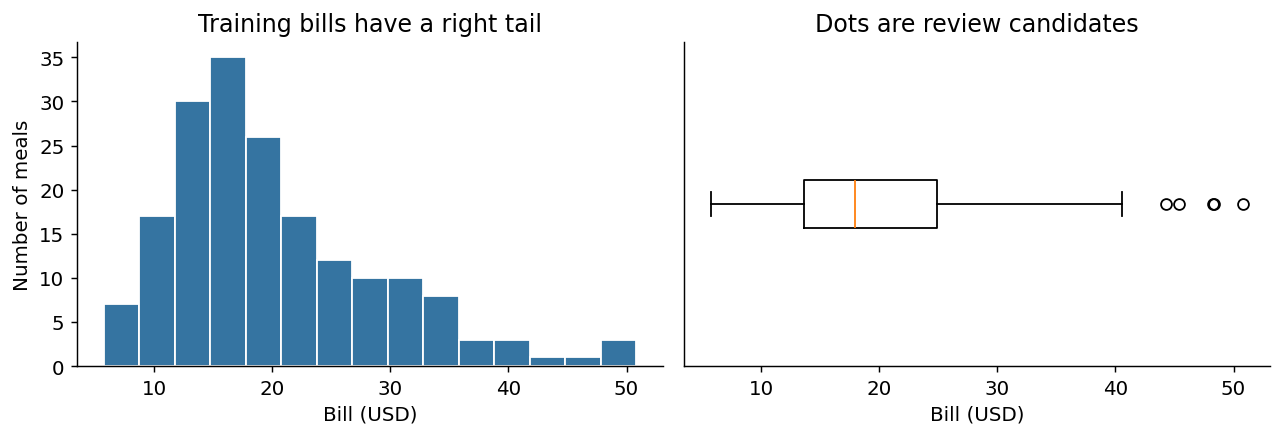

count    183.00
mean      20.27
std        8.87
min        5.75
25%       13.66
50%       17.92
75%       24.86
max       50.81


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(train['total_bill'], bins=15, color='#3574a1', edgecolor='white')
ax[0].set(xlabel='Bill (USD)', ylabel='Number of meals', title='Training bills have a right tail')
ax[1].boxplot(train['total_bill'], orientation='horizontal', whis=1.5)
ax[1].set(xlabel='Bill (USD)', yticks=[], title='Dots are review candidates')
plt.tight_layout(); plt.show()
print(train['total_bill'].describe().round(2).to_string())

## LIVE C · Detect with a transparent rule · 2 minutes
Q1 and Q3 mark the 25th and 75th percentiles. IQR = Q3 − Q1 is the width of the middle 50%.
Flag a value below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. The multiplier is a convention,
not a law, and it is not an estimate of the true error rate. A value exactly on a fence is
not flagged by our strict-inequality rule. pandas uses linear interpolation for quantiles.

Learn limits from **training data only**, then reuse them on held-out/new rows.
A negative lower bill fence does not make negative bills valid: domain rules are separate.

In [3]:
q1, q3 = train['total_bill'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

def flag_bill(frame):
    return (frame['total_bill'] < lower) | (frame['total_bill'] > upper)

train_flag, test_flag = flag_bill(train), flag_bill(test)
print(f'Q1={q1:.4f}, Q3={q3:.4f}, IQR={iqr:.4f}')
print(f'Fences: [{lower:.4f}, {upper:.4f}] USD')
print(f'Train flagged: {train_flag.sum()}/{len(train)}')
print(f'Held-out flagged with SAME limits: {test_flag.sum()}/{len(test)}')
assert np.isclose(upper, 41.6475) and train_flag.sum() == 5

Q1=13.6600, Q3=24.8550, IQR=11.1950
Fences: [-3.1325, 41.6475] USD
Train flagged: 5/183
Held-out flagged with SAME limits: 2/61


## LIVE D · Investigate context before acting · 2 minutes
Would the same bill be equally surprising for one diner and six diners?
The amount per person is a contextual clue, not proof of correctness. Inspect individual rows,
party size, original receipts, units and duplicates before changing anything.
This dataset has no receipts available, so we cannot declare any flagged bill erroneous.

,total_bill,tip,size,day,time,bill_per_person
row_id,,,,,,
170,50.81,10.00,3,Sat,Dinner,16.94
212,48.33,9.00,4,Sat,Dinner,12.08
59,48.27,6.73,4,Sat,Dinner,12.07
182,45.35,3.50,3,Sun,Dinner,15.12
102,44.30,2.50,3,Sat,Dinner,14.77


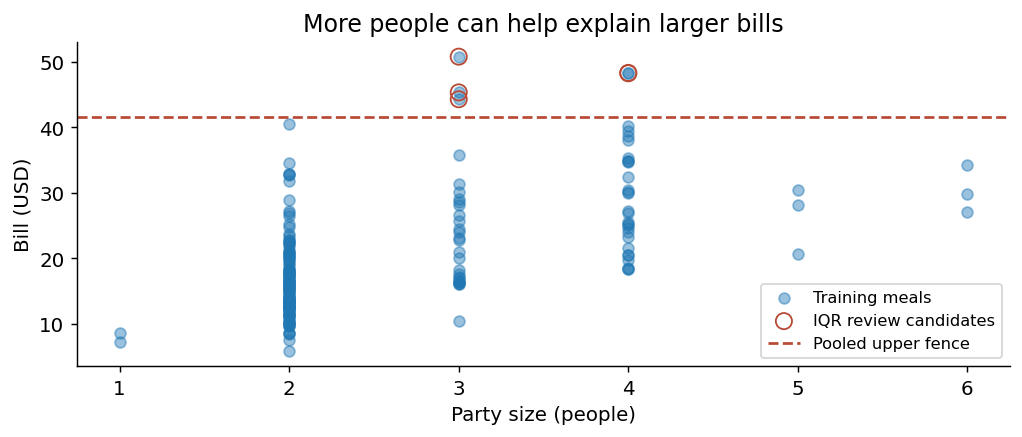

      count  median    max
size                      
1         2    7.92   8.58
2       118   15.61  40.55
3        28   22.96  50.81
4        29   27.20  48.33
5         3   28.15  30.46
6         3   29.80  34.30


In [4]:
review = train.loc[train_flag, ['total_bill','tip','size','day','time']].copy()
review['bill_per_person'] = review['total_bill'] / review['size']
display(review.sort_values('total_bill', ascending=False).round(2))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(train['size'], train['total_bill'], alpha=.45, label='Training meals')
ax.scatter(train.loc[train_flag,'size'], train.loc[train_flag,'total_bill'],
           color='#b84935', s=80, facecolors='none', label='IQR review candidates')
ax.axhline(upper, color='#b84935', ls='--', label='Pooled upper fence')
ax.set(xlabel='Party size (people)', ylabel='Bill (USD)', title='More people can help explain larger bills')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()
print(train.groupby('size')['total_bill'].agg(['count','median','max']).round(2).to_string())

## LIVE E · Compare treatment choices · 3 minutes
Keep the raw data and make separate copies. We compare three **hypotheses**, not three
equally justified cleaning rules:

1. Keep and flag for review: preserves legitimate rare events.
2. Cap a modelling feature at the learned fences: retains rows but loses extreme magnitude.
3. Remove flagged training rows: loses meals and may underrepresent large parties.

We also inspect a log transform: it compresses high amounts without deleting rows.
Logs change units; they do not verify data. Never report capped/logged bills as actual revenue.
The original records remain the authoritative observations.

The plots compare **before treatment versus after removal, capping and log transformation**.
The first three share bin edges and dollar units; the log panel uses a different scale.
Percentile Winsorization caps tails at quantile boundaries; here we demonstrate IQR-based capping.


,rows,mean_bill,median_bill,sum_of_column,share_parties_4_plus
Keep and flag,183.0,20.271,17.920,3709.540,0.191
Cap feature,183.0,20.113,17.920,3680.718,0.191
Remove rows,178.0,19.508,17.685,3472.480,0.185


Interpretation: altered sums describe altered data, not observed revenue.


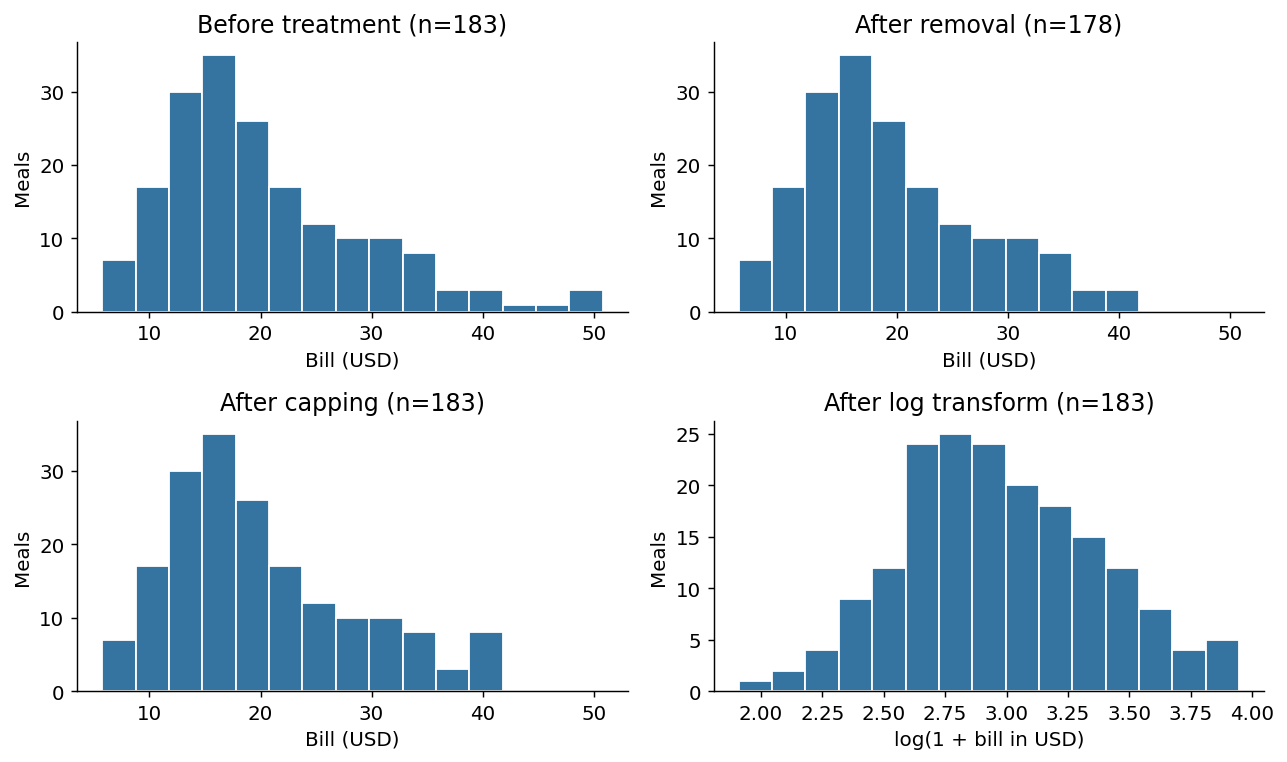

In [5]:
kept = train.assign(bill_flag=train_flag)
capped = train.copy()
capped['total_bill'] = capped['total_bill'].clip(lower=lower, upper=upper)
removed = train.loc[~train_flag].copy()  # illustration only; no evidence these are errors
log_bill = np.log1p(train['total_bill'])

def summary(frame):
    return pd.Series({'rows':len(frame), 'mean_bill':frame['total_bill'].mean(),
                      'median_bill':frame['total_bill'].median(),
                      'sum_of_column':frame['total_bill'].sum(),
                      'share_parties_4_plus':(frame['size']>=4).mean()})

impact = pd.DataFrame({'Keep and flag':summary(kept),
                       'Cap feature':summary(capped),
                       'Remove rows':summary(removed)}).T
display(impact.round(3))
print('Interpretation: altered sums describe altered data, not observed revenue.')
# Reuse the training limits; never fit a second cap on held-out data.
test_capped = test.copy()
test_capped['total_bill'] = test_capped['total_bill'].clip(lower=lower, upper=upper)
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
common_bins = np.linspace(train['total_bill'].min(), train['total_bill'].max(), 16)
views = [
    ('Before treatment', train['total_bill'], False),
    ('After removal', removed['total_bill'], False),
    ('After capping', capped['total_bill'], False),
    ('After log transform', log_bill, True),
]
for a, (title, values, is_log) in zip(axes.flat, views):
    a.hist(values, bins=15 if is_log else common_bins,
           color='#3574a1', edgecolor='white')
    a.set(title=f'{title} (n={len(values)})',
          xlabel='log(1 + bill in USD)' if is_log else 'Bill (USD)',
          ylabel='Meals')
plt.tight_layout(); plt.show()
assert original.equals(df)

## LIVE F · A justified correction and an audit trail · 2 minutes
**Simulated teaching experiment:** on a separate copy only, multiply one training bill by 100
to imitate a cents-versus-dollars error. We know the correct value because we created this error.
In real work, that evidence must come from a receipt, source system, or verified unit definition.
An outlier detector alone cannot tell us to divide by 100.

In [6]:
simulated = train.copy(deep=True)
error_id = train.index[0]
receipt_verified_bill = float(train.loc[error_id, 'total_bill'])
simulated.loc[error_id, 'total_bill'] = 100 * receipt_verified_bill
wrong_value = simulated.loc[error_id, 'total_bill']
print('Simulated wrong value:', wrong_value,
      '| Flagged by training rule:', bool(flag_bill(simulated).loc[error_id]))

corrected = simulated.copy()
corrected.loc[error_id, 'total_bill'] = receipt_verified_bill
audit = pd.DataFrame([{'row_id':error_id, 'column':'total_bill',
                       'before':wrong_value, 'after':receipt_verified_bill,
                       'reason':'Simulated unit error; known source value restored'}])
display(audit)
assert corrected.equals(train) and df.equals(original)
print('Lesson: unusual → investigate → choose an action → preserve the evidence.')

Simulated wrong value: 1730.9999999999998 | Flagged by training rule: True


,row_id,column,before,after,reason
0,115,total_bill,1731.0,17.31,Simulated unit error; known source value restored


Lesson: unusual → investigate → choose an action → preserve the evidence.


## Stop here for the 75 minute class
Ask learners: Does a statistical flag prove a mistake? Why can removal bias the data?
Where should the thresholds be fitted? See the mentor notes for the exit questions and answers.

The next sections are optional self-study, not part of the 13 minute live demo.

## Appendix 1 · Mean, median, z score and MAD · 8 minutes
The mean uses every magnitude, so one extreme value can move it a lot. The median depends on rank.
A z score measures distance from the mean in standard-deviation units. Using |z| > 3 as a flag
is most interpretable for roughly bell-shaped data; skewness and extremes can make it misleading.
Mean and standard deviation can themselves be pulled by extremes (masking).

MAD = median of |x − median(x)|. A modified z score is 0.67449 × (x − median) / MAD.
The 3.5 threshold below is a heuristic, not a guaranteed error boundary.
If SD or MAD is zero, that rule is undefined; do not silently divide by zero or call every row normal.

`scipy.stats.zscore()` below implements the training z scores. The threshold is outside ±3,
meaning z < -3 or z > +3. New rows must reuse training mean and SD rather than calling
`zscore` on each new batch.


In [7]:
from scipy import stats
toy = np.array([10., 12., 12., 13., 15., 100.])
print('Before extreme: mean', toy[:-1].mean(), 'median', np.median(toy[:-1]))
print('With extreme: mean', toy.mean(), 'median', np.median(toy))
x = train['total_bill']
sd = x.std(ddof=0)
mad = np.median(np.abs(x-x.median()))
if sd == 0 or mad == 0:
    raise ValueError('This score is undefined; investigate constant/repeated values.')
z_values = pd.Series(stats.zscore(x.to_numpy(), ddof=0), index=x.index)
z_flag = z_values.abs() > 3
modified_z_flag = (0.67448975*(x-x.median())/mad).abs() > 3.5
display(pd.DataFrame({'IQR':train_flag, 'Z score':z_flag,
                       'Modified Z':modified_z_flag}).sum().to_frame('flagged_training_rows'))

Before extreme: mean 12.4 median 12.0
With extreme: mean 27.0 median 12.5


,flagged_training_rows
IQR,5
Z score,3
Modified Z,5


## Appendix 2 · Optional ML experiment with validation · 15–20 minutes
**For learners who already know train/test splits, regression and cross-validation.**
Question: does capping the bill feature help predict the tip? Target = `tip`; features = `total_bill`
and `size`. Do not use the tip target to select which feature rows to remove.
We compare raw, capped, and log-transformed features using training-only cross-validation (CV).
The capper lives inside each pipeline so every CV fold learns its own limits. Select using CV,
then evaluate that selected pipeline on the held-out test set once. Keep every held-out row,
including large bills. This tiny dataset gives an illustration, not a reliable production conclusion.

Earlier live plots used only training rows. The held-out flag count was a mechanical demonstration;
we have not used its outcomes to tune these candidates. For a real experiment, keep all test data
unseen until this final evaluation. Do not change the experiment after seeing test results.

In [8]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error

class BillCapper(TransformerMixin, BaseEstimator):
    def __init__(self, fold=1.5):
        self.fold = fold
    def fit(self, X, y=None):
        q1_, q3_ = X['total_bill'].quantile([.25,.75])
        spread = q3_ - q1_
        self.lower_ = q1_ - self.fold * spread
        self.upper_ = q3_ + self.fold * spread
        return self
    def transform(self, X):
        result = X.copy()
        result['total_bill'] = result['total_bill'].clip(self.lower_, self.upper_)
        return result

def log_bill_feature(X):
    result = X.copy()
    result['total_bill'] = np.log1p(result['total_bill'])
    return result

X_train, y_train = train[['total_bill','size']], train['tip']
X_test, y_test = test[['total_bill','size']], test['tip']
candidates = {
    'Raw': Pipeline([('model',LinearRegression())]),
    'Capped': Pipeline([('cap',BillCapper()),('model',LinearRegression())]),
    'Log bill': Pipeline([('log',FunctionTransformer(log_bill_feature)),
                         ('model',LinearRegression())])}
cv = KFold(n_splits=5, shuffle=True, random_state=7)
cv_rows = []
for name, pipeline in candidates.items():
    scores = -cross_val_score(pipeline, X_train, y_train, cv=cv,
                              scoring='neg_mean_absolute_error')
    cv_rows.append({'candidate':name,'CV mean MAE USD':scores.mean(),
                    'CV fold SD USD':scores.std()})
cv_results = pd.DataFrame(cv_rows).set_index('candidate')
display(cv_results.round(3))
chosen_name = cv_results['CV mean MAE USD'].idxmin()
chosen = candidates[chosen_name].fit(X_train, y_train)
predictions = chosen.predict(X_test)
print('Selected using CV:', chosen_name)
print('Final held-out MAE (USD):', round(mean_absolute_error(y_test, predictions), 3))
print('All held-out rows retained:', len(predictions) == len(test))
tail = test_flag.to_numpy()
for label, mask in [('Flagged large bills',tail),('Other bills',~tail)]:
    print(label, '| rows:',mask.sum(), '| MAE:',
          round(mean_absolute_error(y_test.to_numpy()[mask], predictions[mask]),3)
          if mask.sum() else 'not available')
print('The tail subgroup is tiny; do not generalize from its MAE.')

,CV mean MAE USD,CV fold SD USD
candidate,,
Raw,0.772,0.072
Capped,0.780,0.088
Log bill,0.765,0.112


Selected using CV: Log bill
Final held-out MAE (USD): 0.669
All held-out rows retained: True
Flagged large bills | rows: 2 | MAE: 0.465
Other bills | rows: 59 | MAE: 0.676
The tail subgroup is tiny; do not generalize from its MAE.


## Practice · 5–10 minutes
1. Change the IQR multiplier to 3 using **training rows only**. What happens to flag count?
2. Is 45 USD for six people as surprising as 45 USD for one person? What else would you ask?
3. Which treatment preserves row count? Which preserves the original amounts?
4. A refund has a negative bill. Should our positive-bill rule always delete it?

<details><summary>Suggested answers</summary>
1. Wider fences cannot increase flags on the same reference values. This is a sensitivity check,
not evidence that 3 is better. 2. Usually less surprising per person, but menus, shared orders,
time and receipts matter. 3. Keep-and-flag, capping and logs retain rows; only keep-and-flag
retains the original bill amounts. 4. First define the table: sales-only versus sales-and-refunds.
A domain rule is valid only for the intended population and units.
</details>

In [9]:
for multiplier in [1.0, 1.5, 3.0]:
    lo, hi = q1 - multiplier*iqr, q3 + multiplier*iqr
    count = ((train['total_bill']<lo)|(train['total_bill']>hi)).sum()
    print(f'Multiplier={multiplier}: {count} training flags')

Multiplier=1.0: 10 training flags
Multiplier=1.5: 5 training flags
Multiplier=3.0: 0 training flags
